In [11]:
from matplotlib import pyplot as plt
from skimage.color import rgb2hed, hed2rgb
from skimage import img_as_float, img_as_ubyte
from skimage import data, io, filters, exposure
from skimage import util
import matplotlib as mp
import numpy as np
import math as mt
from IPython.display import Image

from pylab import *
from scipy import *

from ipywidgets import *

%matplotlib inline

from signals import changeX, changeY, Scenario, Signal, getFinalSignal, plotSingle, plotAllWithNoiseCancel, plotSpectrogram, plotAllWithNoiseCancelWithoutSpectrogram, plotSingleWithoutAll, plotSingleWIFFT, plotAllWithoutAll, plotAll

In [12]:
# ROZWAZANY PRZEDZIAL ([T0, T1])
signalScale = [0.0, 20.0]
# WYSWIETLANA SKALA NA WYKRESIE (DZIEDZINA CZASU)
timePlotXScale = [0.0, 20.0]
# WYSWIETLANA SKALA Y (DZIEDZINA CZASU)
timePloyYScale = [-3.0, 3.0]

# SYGNAL W DZIEDZINIE CZASU

## Podstawowe cechy, czestotliwosc probkowania, Nyquista

**Pytanie** Poniżej możesz zobaczyć sygnał wraz z jego przesunięciem. Wyjaśnij poniższe pojęcia i zaznacz je na wykresie i/lub podaj ich wartość:
a) amplituda
b) częstotliwość
c) faza
d) okres

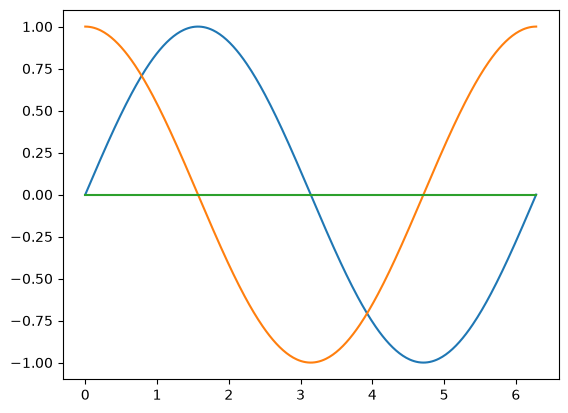

In [13]:
t = np.linspace(0,2*mt.pi,400)
a = np.sin(t)
b = np.cos(t)
c = [0]*400

plt.plot(t, a, t, b, t, c)
plt.show()

**Pytanie** Czy pamiętasz czym jest częstotliwość próbkowania i częstotliwość Nyquista?

In [14]:
def rate_sin(Fs):
    T = 1/Fs # sampling period
    t = 0.1 # seconds of sampling
    N = Fs*t # total points in signal

    # signal information
    freq = 20 # in hertz, the desired natural frequency
    omega = 2*np.pi*freq # angular frequency for sine waves

    t_vec = np.arange(N)*T # time vector for plotting
    y = np.sin(omega*t_vec)
    return t_vec, y

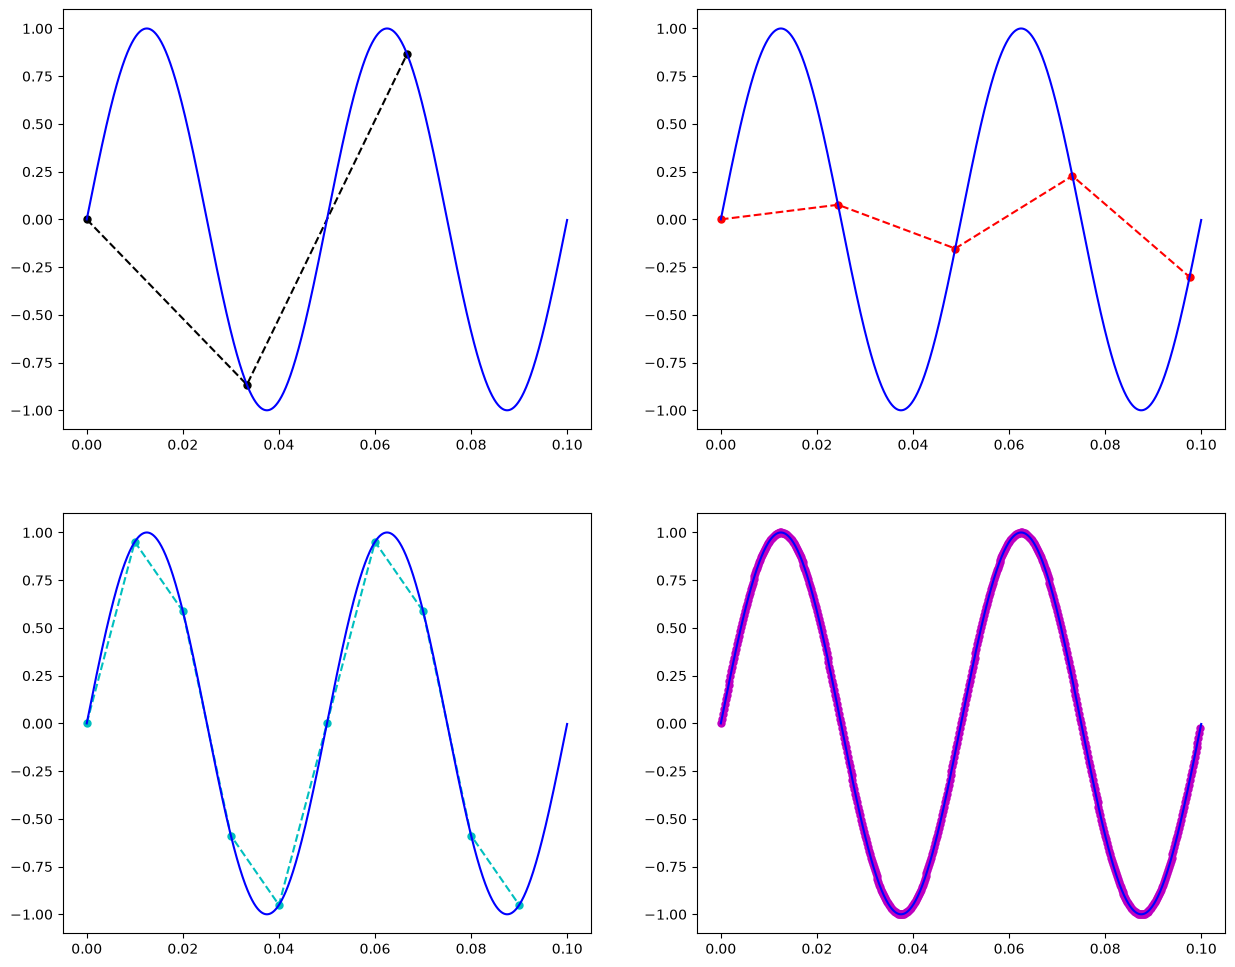

In [15]:
fs = [30, 41, 100, 5000] # sample rate

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(15,12))

y_val = []
t_vec_val = []
for i in fs:
    t_vec, y = rate_sin(i)
    y_val.append(y)
    t_vec_val.append(t_vec)

tv, yy = rate_sin(40000)

colors = [['ko--', 'ro--'],['co--', 'mo--'] ]
k = 0
for i in range(2):
    for j in range(2):
        ax[i, j].plot(t_vec_val[k],y_val[k], colors[i][j], markersize=5)
        ax[i, j].plot(tv, yy, 'b')
        k += 1

plt.show()

In [ ]:
interact(plotSingleWithoutAll, amplitude=(0.5,2.5,0.1),
         frequency=(0.1, 2.0,0.1),phase = (-2.0 * mt.pi, 2.0*mt.pi, 0.25),
         yTranslation = (-2.5, 2.5, 0.5), samplingFrequency=(0.25,10,0.25));

interactive(children=(FloatSlider(value=1.0, description='amplitude', max=2.5, min=0.5), FloatSlider(value=0.5…

$$u(t) = A \cdot sin(2\cdot \pi \cdot f_{0} \cdot t + \varphi) + y_{0}$$

Jaka musi być częstotliwość sygnału, aby jego przebieg się (jeden, pełen okres) się skończył w 5s?

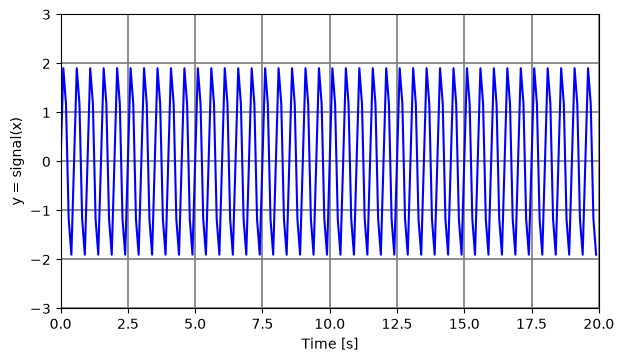

In [17]:
x = 2
plotSingleWithoutAll( 2, frequency = x, phase = 0, yTranslation = 0, samplingFrequency=10)

Jaka musi być częstotliwość sygnału, aby jego przebieg się (jeden, pełen) się skończył w 0.5s?

## Sumowanie sygnałow

In [18]:
sc1 = Scenario([
        Signal(amplitude = 1.0, frequency = 0.5, phase = 0.0, yTranslation = 0.0, color = 'blue'),
        Signal(amplitude = 2.0, frequency = 0.25, phase = 0.0, yTranslation = 0.0, color = 'green') ])
sc2 = Scenario([
        Signal(amplitude = 1.0, frequency = 0.5, phase = 0.0, yTranslation = 0.0, color = 'blue'),
        Signal(amplitude = 1.25, frequency = 0.5, phase = 0.0, yTranslation = 0.0, color = 'green') ])
sc3 = Scenario([
        Signal(amplitude = 1.0, frequency = 0.5, phase = 0.0, yTranslation = 0.0, color = 'blue'),
        Signal(amplitude = 1.0, frequency = 0.5, phase = mt.pi, yTranslation = 0.0, color = 'green') ])



scenarios = {"1. Przyklad": sc1 , "2. Wzmocnienie" : sc2, "3. Tlumienie" : sc3}
interact(plotAllWithoutAll, scenario=scenarios, samplingFrequency=(0.25,10,0.25));



interactive(children=(Dropdown(description='scenario', options={'1. Przyklad': Scenario(), '2. Wzmocnienie': S…

# Sygnal w dziedzinie czestotliwosci

## Omowienie podstaw

In [ ]:
#FFT
interact(plotSingleWIFFT, amplitude=(0.5,2.5,0.1),
         frequency=(0.0, 2.0,0.1),phase = (-2.0 * mt.pi, 2.0*mt.pi, 0.25),
         yTranslation = (-2.5, 2.5, 0.5), samplingFrequency=(0.25,10,0.25));

interactive(children=(FloatSlider(value=1.0, description='amplitude', max=2.5, min=0.5), FloatSlider(value=0.5…

In [20]:
#https://pl.wikipedia.org/wiki/Twierdzenie_Kotielnikowa-Shannona

## Suma sygnalow w dziedzinie czasu a efekt w dziedzinie czasu.

## Odwrotne FFT

In [21]:


sc1 = Scenario([
        Signal(amplitude = 1.0, frequency = 0.5, phase = 0.0, yTranslation = 0.0, color = 'blue'),
        Signal(amplitude = 2.0, frequency = 0.25, phase = 0.0, yTranslation = 0.0, color = 'green') ])
sc2 = Scenario([
        Signal(amplitude = 1.0, frequency = 0.5, phase = 0.0, yTranslation = 0.0, color = 'blue'),
        Signal(amplitude = 1.25, frequency = 0.5, phase = 0.0, yTranslation = 0.0, color = 'green') ])
sc3 = Scenario([
        Signal(amplitude = 1.0, frequency = 0.5, phase = 0.0, yTranslation = 0.0, color = 'blue'),
        Signal(amplitude = 1.0, frequency = 0.5, phase = mt.pi, yTranslation = 0.0, color = 'green') ])

scenarios = {"1. Przyklad": sc1 , "2. Wzmocnienie" : sc2, "3. Tlumienie" : sc3}
interact(plotAll, scenario=scenarios, samplingFrequency=(0.25,10,0.25));




interactive(children=(Dropdown(description='scenario', options={'1. Przyklad': Scenario(), '2. Wzmocnienie': S…

In [22]:
x = np.arange(0, 2 * 2*np.pi, 0.1)
y = np.sin(x)
print(y)

[ 0.          0.09983342  0.19866933  0.29552021  0.38941834  0.47942554
  0.56464247  0.64421769  0.71735609  0.78332691  0.84147098  0.89120736
  0.93203909  0.96355819  0.98544973  0.99749499  0.9995736   0.99166481
  0.97384763  0.94630009  0.90929743  0.86320937  0.8084964   0.74570521
  0.67546318  0.59847214  0.51550137  0.42737988  0.33498815  0.23924933
  0.14112001  0.04158066 -0.05837414 -0.15774569 -0.2555411  -0.35078323
 -0.44252044 -0.52983614 -0.61185789 -0.68776616 -0.7568025  -0.81827711
 -0.87157577 -0.91616594 -0.95160207 -0.97753012 -0.993691   -0.99992326
 -0.99616461 -0.98245261 -0.95892427 -0.92581468 -0.88345466 -0.83226744
 -0.77276449 -0.70554033 -0.63126664 -0.55068554 -0.46460218 -0.37387666
 -0.2794155  -0.1821625  -0.0830894   0.0168139   0.1165492   0.21511999
  0.31154136  0.40484992  0.49411335  0.57843976  0.6569866   0.72896904
  0.79366786  0.85043662  0.8987081   0.93799998  0.96791967  0.98816823
  0.99854335  0.99894134  0.98935825  0.96988981  0

In [23]:
np.fft.ifft(np.fft.fft(y))

array([-1.76225877e-18+5.25442234e-17j,  9.98334166e-02-2.35240894e-16j,
        1.98669331e-01-1.24638011e-16j,  2.95520207e-01-2.29757311e-17j,
        3.89418342e-01-4.84350751e-17j,  4.79425539e-01-2.77916186e-16j,
        5.64642473e-01-7.01959685e-17j,  6.44217687e-01+6.34395111e-17j,
        7.17356091e-01-2.82892734e-16j,  7.83326910e-01-2.71334334e-16j,
        8.41470985e-01-1.32442218e-16j,  8.91207360e-01-2.64929086e-17j,
        9.32039086e-01-1.68025621e-16j,  9.63558185e-01-1.58560182e-16j,
        9.85449730e-01+6.01607354e-17j,  9.97494987e-01-5.16221788e-17j,
        9.99573603e-01-2.86402356e-17j,  9.91664810e-01-6.84537250e-17j,
        9.73847631e-01-3.25420927e-17j,  9.46300088e-01+2.29106861e-16j,
        9.09297427e-01+1.19095707e-16j,  8.63209367e-01+5.66637130e-17j,
        8.08496404e-01+2.41909694e-17j,  7.45705212e-01+7.27714447e-17j,
        6.75463181e-01-1.12132074e-16j,  5.98472144e-01+5.65631001e-17j,
        5.15501372e-01+4.67291968e-16j,  4.27379880

In [24]:
yp = np.fft.ifft(np.fft.fft(y))
print(y)

[ 0.          0.09983342  0.19866933  0.29552021  0.38941834  0.47942554
  0.56464247  0.64421769  0.71735609  0.78332691  0.84147098  0.89120736
  0.93203909  0.96355819  0.98544973  0.99749499  0.9995736   0.99166481
  0.97384763  0.94630009  0.90929743  0.86320937  0.8084964   0.74570521
  0.67546318  0.59847214  0.51550137  0.42737988  0.33498815  0.23924933
  0.14112001  0.04158066 -0.05837414 -0.15774569 -0.2555411  -0.35078323
 -0.44252044 -0.52983614 -0.61185789 -0.68776616 -0.7568025  -0.81827711
 -0.87157577 -0.91616594 -0.95160207 -0.97753012 -0.993691   -0.99992326
 -0.99616461 -0.98245261 -0.95892427 -0.92581468 -0.88345466 -0.83226744
 -0.77276449 -0.70554033 -0.63126664 -0.55068554 -0.46460218 -0.37387666
 -0.2794155  -0.1821625  -0.0830894   0.0168139   0.1165492   0.21511999
  0.31154136  0.40484992  0.49411335  0.57843976  0.6569866   0.72896904
  0.79366786  0.85043662  0.8987081   0.93799998  0.96791967  0.98816823
  0.99854335  0.99894134  0.98935825  0.96988981  0

## Spectrogram

In [25]:

sc1 = Scenario([
        Signal(amplitude = 1.0, frequency = 0.5, phase = 0.0, yTranslation = 0.0, color = 'blue',
               changeX=changeX(5,15,10))])
sc2 = Scenario([
        Signal(amplitude = 1.0, frequency = 0.5, phase = 0.0, yTranslation = 0.0, color = 'blue',
               changeY=changeY(5,15,1))])
sc3 = Scenario([
        Signal(amplitude = 1.0, frequency = 0.5, phase = 0.0, yTranslation = 0.0, color = 'blue',
               changeX=changeX(10,20,10), changeY=changeY(0,10,1))])

sc4 = Scenario([
        Signal(amplitude = 2.0, frequency = 0.5, phase = 0.0, yTranslation = 0.0, color = 'blue',
               changeX=changeX(5,15,10))])

scenarios = {"1. Czestotliwosc": sc1, "2. Przesunięcie Y": sc2, "3. Mix": sc3, "4. Amplituda": sc4    }
interact(plotSpectrogram, scenario=scenarios, samplingFrequency=(0.25,10,0.25), windowSize=(4.0,10.0,0.25),
         windowJump=(0.25,2.0,0.25));


interactive(children=(Dropdown(description='scenario', options={'1. Czestotliwosc': Scenario(), '2. Przesunięc…

In [26]:
#https://pl.wikipedia.org/wiki/Okno_czasowe